# COMP3991 Lab 5 — Vectors and vector multiplication

**Week 5 · 2 hours · follows Lecture 5**

Notation and laws come from Cohen, *Linear Algebra: Theory, Intuition, Code* (2021). The lecture used the same symbols; this lab does too.

| Item | Detail |
|---|---|
| Syllabus | 4.0–4.5 Vectors; 5.0–5.9 Vector multiplication |
| Cohen | Ch. 2 (pp. 21–42); Ch. 3 (pp. 43–73) |
| Companion notebooks | [LAbookX_chapter02.ipynb](https://github.com/mikexcohen/LinAlgBook/blob/main/python/LAbookX_chapter02.ipynb) · [LAbookX_chapter03.ipynb](https://github.com/mikexcohen/LinAlgBook/blob/main/python/LAbookX_chapter03.ipynb) |
| YouTube | [Python for linear algebra (for absolute beginners)](https://www.youtube.com/watch?v=JSjWltL9-7M) |

Run this notebook in **Google Colab** or locally with `numpy` and `matplotlib`.

**How this notebook is organised.** Each task has **questions**, a **templated code cell** (complete every `TODO` — running the cell as-is will fail), written answers, then **Solutions (tutor)** with the worked algebra *and* the complete code. Tutors: delete or hide every **Solutions (tutor)** cell before distributing.

There are **five** student tasks (plus a short setup). Suggested timing:

| Minutes | Task |
|---|---|
| 0–8 | Setup and notation |
| 8–28 | Task 1 Transpose, add, scale |
| 28–48 | Task 2 Dot product and magnitude |
| 48–70 | Task 3 Angle, unit vectors, cosine similarity |
| 70–90 | Task 4 Linear weighted combination and $\hat{y}=w^{\mathrm{T}}x$ |
| 90–120 | Task 5 Outer, Hadamard, toy word embeddings |


## Notation used in this lab

Every abbreviation below is defined here and then used without re-explaining it.

| Symbol / phrase | Cohen / here | Meaning |
|---|---|---|
| $\lambda$, $\alpha$, $\gamma$ | §2.1 | **scalars** (ordinary numbers) |
| $v$, $a$, $b$ | §2.2 | **vectors** (ordered lists of numbers) |
| dimensionality | §2.2 | how many components |
| $v^{\mathrm{T}}$ | §2.3 | **transpose**: column $\leftrightarrow$ row |
| $a+b$ | (2.2) | componentwise sum |
| $\lambda v$ | (2.3) | scalar–vector multiplication |
| $a\cdot b=\langle a,b\rangle=a^{\mathrm{T}}b$ | (3.1) | **dot** / **inner** product $\sum a_i b_i$ |
| $\lVert a\rVert$ | (3.2) | **magnitude**; $a^{\mathrm{T}}a=\lVert a\rVert^{2}$ |
| Cauchy–Schwarz | (3.14) | $\lvert a^{\mathrm{T}}b\rvert\le\lVert a\rVert\,\lVert b\rVert$ |
| $\theta$ | (3.15)–(3.16) | angle between two vectors |
| orthogonal, $\perp$ | (3.17) | $a^{\mathrm{T}}b=0$ |
| collinear | §3.3 | $\theta=0$ or $\pi$ |
| cosine similarity $\mathrm{sim}(a,b)$ | from (3.16) | $\cos\theta=(a^{\mathrm{T}}b)/(\lVert a\rVert\lVert b\rVert)$ |
| embedding $e_{\mathrm{word}}$ | Lecture 5 | vector that stands for an object (word, item, …) |
| linear weighted combination | (3.35) | $w=\sum_i\lambda_i v_i$ |
| $vw^{\mathrm{T}}$ | (3.36) | **outer** product (a matrix); $(vw^{\mathrm{T}})_{i,j}=v_i w_j$ |
| $a\odot b$ | (3.37) | **Hadamard** (elementwise) product |
| $a\times b$ | (3.38) | **cross** product ($\mathbb{R}^{3}$ only) |
| $\hat{v}$ | (3.41) | **unit** vector $v/\lVert v\rVert$ |
| **d.n.e.** | calculus §4.5 | **d**oes **n**ot **e**xist |
| $\hat{y}$ | Labs 1–4 | **prediction** (what the recipe currently says) |
| $w$ | Labs 1–4 | **weight** (the knob); not the prediction |
| $C=(\hat{y}-y)^{2}$ | Labs 1–4 | squared-error **cost** |

**Convention.** Column vectors are the default (Cohen §2.3). If an operation is invalid (unequal length for add / dot / Hadamard; unit vector of the zero vector; angle or cosine similarity with a zero vector), write **d.n.e.** Never write an undefined “DNE”.

In code, return the Python string `"d.n.e."` for those cases.


## Task 0 — Setup (questions)

Run the next cell. If you are on Colab and a package is missing, uncomment the `pip` line.

**0a.** Cohen §2.3: a column and its transpose are different objects. What does `v.T` do when `v` is a **1D** NumPy array of shape `(3,)`? What do you need instead to force a column?

**0b.** In this lab, $w$ means a **weight** (scalar or vector of weights). What letter is the prediction?


In [ ]:
# %pip install numpy matplotlib

import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
DNE = "d.n.e."  # does not exist (never write an undefined "DNE")

v = np.array([1.0, 2.0, 3.0])
print("v        ", v, "shape", v.shape)
print("v.T      ", v.T, "shape", v.T.shape)
print("column   ", v.reshape(-1, 1), "shape", v.reshape(-1, 1).shape)
print("numpy", np.__version__)


v         [1. 2. 3.] shape (3,)
v.T       [1. 2. 3.] shape (3,)
column    [[1.]
 [2.]
 [3.]] shape (3, 1)
numpy 2.1.3


**Your answer (Task 0)**

- 0a:
- 0b:


### Solutions (tutor) — Task 0

**0a.** On a 1D array, `.T` does **not** create a column: `v` and `v.T` both have shape `(3,)`. NumPy 1D arrays have no intrinsic orientation (Cohen Ch. 2). Force a column with `v.reshape(-1, 1)` (shape `(3, 1)`).

**0b.** The prediction is $\hat{y}$. Cost is $C$. Learning rate (from Labs 2–3) is $\eta$ if it appears; it does not appear this week.


## Task 1 — Transpose, add, scale (questions)

Cohen §2.3–§2.5. Implement addition and (2.3) **with a loop** (do not call `a + b` or `lam * v` inside the functions). If the dimensionalities differ, the operation is **d.n.e.**

**1a.** Let $a=\begin{bmatrix}1\\2\end{bmatrix}$ and $b=\begin{bmatrix}3\\4\end{bmatrix}$. Compute $a+b$ by hand, then with your function. Cohen §2.4.

**1b.** Compute $3\begin{bmatrix}-1\\3\\0\\2\end{bmatrix}$ by hand (Cohen §2.5), then with your function.

**1c.** What is $\begin{bmatrix}1\\2\end{bmatrix}+\begin{bmatrix}1\\2\\3\end{bmatrix}$? Write the correct shorthand.

**1d.** Compute $a-b$ using `add_vectors(a, scale_vector(-1, b))`. Is subtraction commutative?


In [ ]:
# Task 1 — complete the TODOs.

def add_vectors(a, b):
    """Componentwise sum. Return DNE if lengths differ."""
    a = np.asarray(a, dtype=float).reshape(-1)
    b = np.asarray(b, dtype=float).reshape(-1)
    if a.size != b.size:
      return DNE
    out = np.empty(a.size)
    for i in range(a.size):
      out[i] = a[i] + b[i]
    return out
    #raise NotImplementedError("Task 1: add_vectors")


def scale_vector(lam, v):
    """Cohen (2.3): multiply every component by lam."""
    v = np.asarray(v, dtype=float).reshape(-1)
    # TODO: build lam * v with a for-loop (not lam*v)
    out = np.empty(v.size)
    for i in range(v.size):
      out[i] = lam * v[i]
    return out
    #raise NotImplementedError("Task 1: scale_vector")


a = np.array([1.0, 2.0])
b = np.array([3.0, 4.0])
print("1a  a+b =", add_vectors(a, b))

u = np.array([-1.0, 3.0, 0.0, 2.0])
print("1b  3u  =", scale_vector(3, u))

print("1c  unequal =", add_vectors([1, 2], [1, 2, 3]))

print("1d  a-b =", add_vectors(a, scale_vector(-1, b)))
print("1d  b-a =", add_vectors(b, scale_vector(-1, a)))


1a  a+b = [4. 6.]
1b  3u  = [-3.  9.  0.  6.]
1c  unequal = d.n.e.
1d  a-b = [-2. -2.]
1d  b-a = [2. 2.]


**Your answer (Task 1)**

- 1a (by hand):
- 1b (by hand):
- 1c:
- 1d:


## Task 2 — Dot product and magnitude (questions)

Cohen (3.1): $\alpha=a^{\mathrm{T}}b=\sum_{i=1}^{n}a_i b_i$. Cohen (3.2): $\lVert a\rVert=\sqrt{a^{\mathrm{T}}a}$.

Implement `dot_product` with a **loop** (do not call `np.dot` or `@` inside the function). If the lengths differ, return `"d.n.e."`.

**2a.** Compute $\begin{bmatrix}1\\2\\3\\4\end{bmatrix}\cdot\begin{bmatrix}5\\6\\7\\8\end{bmatrix}$ by hand (Cohen §3.1), then with your function.

**2b.** Let $c=\begin{bmatrix}3\\4\end{bmatrix}$. Compute $\lVert c\rVert$ from (3.2) using your `dot_product` (not `np.linalg.norm`).

**2c.** What is $\begin{bmatrix}1\\2\end{bmatrix}^{\mathrm{T}}\begin{bmatrix}1\\2\\3\end{bmatrix}$?

**2d.** Check commutativity: is `dot_product(a, b)` equal to `dot_product(b, a)` for the vectors in 2a?

**2e.** Cohen (3.4) says the three-vector grouping $u^{\mathrm{T}}(v^{\mathrm{T}}w)$ is **not** in general equal to $(u^{\mathrm{T}}v)^{\mathrm{T}}w$. In one sentence: what goes wrong if you casually write $a\cdot b\cdot c$?


In [ ]:
# Task 2 — complete the TODOs.

def dot_product(a, b):
    """Cohen (3.1). Return DNE if lengths differ."""
    a = np.asarray(a, dtype=float).reshape(-1)
    b = np.asarray(b, dtype=float).reshape(-1)
    # TODO: if lengths differ, return DNE
    if a.size != b.size:
      return DNE
    # TODO: otherwise accumulate sum a[i]*b[i] in a loop
    s = 0.0
    for i in range(a.size):
      s += a[i] * b[i]
    return s
    #raise NotImplementedError("Task 2: dot_product")


def magnitude(a):
    """Cohen (3.2): sqrt(a^T a)."""
    # TODO: use dot_product; magnitude is never DNE for a finite vector
    d = dot_product(a, a)
    return float(np.sqrt(d))
    #raise NotImplementedError("Task 2: magnitude")


p = np.array([1.0, 2.0, 3.0, 4.0])
q = np.array([5.0, 6.0, 7.0, 8.0])
print("2a  p·q =", dot_product(p, q), "  (expect 70)")
print("2a  np.dot check", np.dot(p, q))

c = np.array([3.0, 4.0])
print("2b  ||c|| =", magnitude(c), "  (expect 5)")

print("2c  unequal =", dot_product([1, 2], [1, 2, 3]))
print("2d  commutative?", dot_product(p, q), dot_product(q, p))


2a  p·q = 70.0   (expect 70)
2a  np.dot check 70.0
2b  ||c|| = 5.0   (expect 5)
2c  unequal = d.n.e.
2d  commutative? 70.0 70.0


**Your answer (Task 2)**

- 2a (by hand):
- 2b:
- 2c:
- 2d:
- 2e:


## Task 3 — Angle, orthogonality, unit vectors, cosine similarity (questions)

Cohen (3.15): $a^{\mathrm{T}}b=\lVert a\rVert\lVert b\rVert\cos(\theta)$.
Cohen (3.16): $\theta=\arccos\bigl((a^{\mathrm{T}}b)/(\lVert a\rVert\lVert b\rVert)\bigr)$ with $\theta\in[0,\pi]$.
Cohen (3.17): $a\perp b$ if and only if $a^{\mathrm{T}}b=0$.
Cohen (3.41): $\hat{v}=v/\lVert v\rVert$. If $\lVert v\rVert=0$, the unit vector is **d.n.e.** If either magnitude is $0$, the angle in (3.16) and the cosine similarity are **d.n.e.** (division by zero).

**Cosine similarity** is the cosine in (3.16), the quantity retrieval systems report:
$$
\mathrm{sim}(a,b)=\frac{a^{\mathrm{T}}b}{\lVert a\rVert\lVert b\rVert}=\cos\theta.
$$
By Cauchy–Schwarz (3.14) this lies in $[-1,1]$ when it exists.

Reuse `dot_product` and `magnitude` from Task 2 (re-run that cell if needed).

Let $a=\begin{bmatrix}1\\0\end{bmatrix}$, $b=\begin{bmatrix}0\\2\end{bmatrix}$, $c=\begin{bmatrix}3\\4\end{bmatrix}$.

**3a.** Compute $a^{\mathrm{T}}b$ and decide whether $a\perp b$.

**3b.** Compute $\theta$ between $a$ and $c$. Leave it as `arccos(...)` in the written answer if you wish; print the radian value from code.

**3c.** Cohen §3.9: $v=\begin{bmatrix}0\\2\end{bmatrix}$. Write $\hat{v}$.

**3d.** What is the unit vector of the **zero** vector? Why?

**3e.** Plot $a$, $b$, and $c$ in standard position (origin to tip). You should see $a$ along the $x$-axis and $b$ along the $y$-axis.

**3f.** Implement `cosine_similarity`. Print $\mathrm{sim}(a,c)$ (expect $3/5$) and $\mathrm{sim}(a,0)$ (expect **d.n.e.**).


3a  a·b = 0.0   orthogonal? True
3b  theta (rad) = 0.9272952180016123   arccos(3/5) check 0.9272952180016123
3c  hat v = [0. 1.]
3d  hat 0 = d.n.e.
3f  sim(a,c) = 0.6   sim(a,0) = d.n.e.


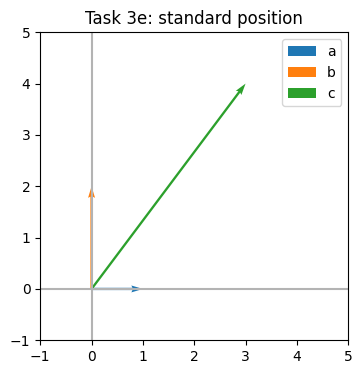

In [ ]:
# Task 3 — complete the TODOs. Requires Task 2 functions.

def angle_between(a, b):
    """Cohen (3.16). Return DNE if either magnitude is 0."""
    # TODO: mag_a, mag_b, then if either is 0 return DNE
    mag_a = magnitude(a)
    mag_b = magnitude(b)
    if mag_a == 0.0 or mag_b == 0.0:
      return DNE
    # TODO: use dot_product
    cos_th = dot_product(a, b) / (mag_a * mag_b)
    # TODO: return np.arccos(dot / (mag_a * mag_b))
    cos_th = float(np.clip(cos_th, -1.0, 1.0))
    # clip the cosine into [-1, 1] to avoid tiny numeric overshoot
    return float(np.arccos(cos_th))
    #raise NotImplementedError("Task 3: angle_between")


def is_orthogonal(a, b, tol=1e-12):
    """Cohen (3.17). True iff a^T b is (numerically) 0."""
    # TODO: use dot_product; if DNE, the test itself is DNE
    d = dot_product(a, b)
    if d is DNE:
      return DNE
    return abs(d) < tol
    #raise NotImplementedError("Task 3: is_orthogonal")


def unit_vector(v):
    """Cohen (3.41). Return DNE for the zero vector."""
    # TODO
    mag = magnitude(v)
    if mag == 0.0:
                 return DNE
    return scale_vector(1.0 / mag, v)
    #raise NotImplementedError("Task 3: unit_vector")


def cosine_similarity(a, b):
    """sim(a,b) = cos theta from (3.16). Return DNE if either magnitude is 0."""
    # TODO: do not call np.dot; use your dot_product / magnitude
    mag_a = magnitude(a)
    mag_b = magnitude(b)
    if mag_a == 0.0 or mag_b == 0.0:
      return DNE
    val = dot_product(a, b) / (mag_a * mag_b)
    return float(np.clip(val, -1.0, 1.0))
    #raise NotImplementedError("Task 3: cosine_similarity")


a = np.array([1.0, 0.0])
b = np.array([0.0, 2.0])
c = np.array([3.0, 4.0])
print("3a  a·b =", dot_product(a, b), "  orthogonal?", is_orthogonal(a, b))

th = angle_between(a, c)
print("3b  theta (rad) =", th, "  arccos(3/5) check", np.arccos(0.6))

v = np.array([0.0, 2.0])
print("3c  hat v =", unit_vector(v))
print("3d  hat 0 =", unit_vector(np.array([0.0, 0.0])))
print("3f  sim(a,c) =", cosine_similarity(a, c), "  sim(a,0) =", cosine_similarity(a, np.zeros(2)))

# 3e — standard-position arrows
fig, ax = plt.subplots(figsize=(4, 4))
ax.axhline(0, color="0.7")
ax.axvline(0, color="0.7")
ax.quiver(0, 0, a[0], a[1], angles="xy", scale_units="xy", scale=1, color="C0", label="a")
ax.quiver(0, 0, b[0], b[1], angles="xy", scale_units="xy", scale=1, color="C1", label="b")
ax.quiver(0, 0, c[0], c[1], angles="xy", scale_units="xy", scale=1, color="C2", label="c")
ax.set_xlim(-1, 5)
ax.set_ylim(-1, 5)
ax.set_aspect("equal")
ax.legend()
ax.set_title("Task 3e: standard position")
plt.show()


**Your answer (Task 3)**

- 3a:
- 3b:
- 3c:
- 3d:
- 3e (what the plot shows):
- 3f:


## Task 4 — Linear weighted combination and $\hat{y}=w^{\mathrm{T}}x$ (questions)

Cohen (3.35):
$$
z=\lambda_1 v_1+\lambda_2 v_2+\cdots+\lambda_m v_m=\sum_{i=1}^{m}\lambda_i v_i.
$$
The $\lambda_i$ are **weights** (scalars). The result is a vector. (In COMP3991 modelling we still reserve the letter $w$ for **weights** and $\hat{y}$ for the **prediction** — see 4c.)

Implement `linear_combination` by calling your `scale_vector` and `add_vectors` (no `np.dot` stacked vectors unless you are checking).

**4a.** Cohen §3.5: $\lambda=(1,2,-3)$ and
$$
v_1=\begin{bmatrix}4\\5\\1\end{bmatrix},\;
v_2=\begin{bmatrix}-4\\0\\-4\end{bmatrix},\;
v_3=\begin{bmatrix}1\\3\\2\end{bmatrix}.
$$
Compute the combination by hand (at least check the third component), then with code.

**4b.** Lab 1 used one feature $x=3$ and one weight $w=1$, so $\hat{y}=wx=3$. Write the **same** calculation as a dot product of two 1-vectors. What are those two vectors?

**4c.** Lab 3 used two weights: $\hat{y}=w_1 x+w_2$. Take the feature-and-intercept vector $x=\begin{bmatrix}3\\1\end{bmatrix}$ and $w=\begin{bmatrix}1\\0\end{bmatrix}$. Compute $\hat{y}=w^{\mathrm{T}}x$. Compare with Lab 1.

**4d.** If the $v_i$ do not all have the same length, the combination is **d.n.e.** Demonstrate with a short example.


In [ ]:
# Task 4 — complete the TODOs. Requires Tasks 1–2.

def linear_combination(lambdas, vectors):
    """Cohen (3.35). lambdas: sequence of scalars; vectors: sequence of vectors."""
    # TODO: start from the zero vector of the right length
    # TODO: repeatedly add scale_vector(lam, v)
    # TODO: if any add is DNE, return DNE
    lambdas = list(lambdas)
    vectors = [np.asarray(v, dtype=float).reshape(-1) for v in vectors]
    if len(lambdas) == 0 or len(lambdas) != len(vectors):
      return DNE
    acc = scale_vector(lambdas[0], vectors[0])
    for lam, vec in zip(lambdas[1:], vectors[1:]):
      acc = add_vectors(acc, scale_vector(lam, vec))
      if acc is DNE or (isinstance(acc, str) and acc == DNE):
        return DNE
    return acc
    #raise NotImplementedError("Task 4: linear_combination")


lams = [1.0, 2.0, -3.0]
v1 = np.array([4.0, 5.0, 1.0])
v2 = np.array([-4.0, 0.0, -4.0])
v3 = np.array([1.0, 3.0, 2.0])
print("4a  combination =", linear_combination(lams, [v1, v2, v3]))

# 4b — Lab 1 as a 1D dot product
w_lab1 = np.array([1.0])  # TODO: np.array([...])
x_lab1 = np.array([3.0])  # TODO
yhat_lab1 = dot_product(w_lab1, x_lab1)  # TODO: dot_product(...)
if w_lab1 is None or x_lab1 is None or yhat_lab1 is None:
    raise NotImplementedError("Task 4b: Lab 1 as a dot product")
print("4b  yhat =", yhat_lab1)

# 4c — two weights, intercept dummy 1
w_two = np.array([1.0, 0.0])
x_two = np.array([3.0, 1.0])
print("4c  yhat =", dot_product(w_two, x_two))

print("4d  unequal =", linear_combination([1.0, 1.0], [np.array([1.0, 2.0]), np.array([1.0])]))


4a  combination = [ -7.  -4. -13.]
4b  yhat = 3.0
4c  yhat = 3.0
4d  unequal = d.n.e.


**Your answer (Task 4)**

- 4a (by hand / third component):
- 4b:
- 4c:
- 4d:


## Task 5 — Outer, Hadamard, and toy word embeddings (questions)

Four products, four outputs (Lecture 5):

| Name | Cohen | Output |
|---|---|---|
| inner / dot | (3.1) $a^{\mathrm{T}}b$ | scalar |
| outer | (3.36) $vw^{\mathrm{T}}$, $(vw^{\mathrm{T}})_{i,j}=v_i w_j$ | matrix |
| Hadamard | (3.37) $a\odot b$ | vector |
| cross | (3.38) $a\times b$ | vector in $\mathbb{R}^{3}$ only |

Implement `hadamard` and `outer_product` with **loops**. If Hadamard lengths differ, return `"d.n.e."`. Reuse `cosine_similarity` and `linear_combination` from earlier tasks.

**5a.** Cohen §3.7: compute
$\begin{bmatrix}3\\6\\9\\0\end{bmatrix}\odot\begin{bmatrix}2\\-2\\4\\-4\end{bmatrix}$
by hand, then with code. In NumPy, `*` is Hadamard — you may check with `*` *after* your loop works.

**5b.** Compute the outer product $\begin{bmatrix}1\\2\end{bmatrix}\begin{bmatrix}3&4\end{bmatrix}$. How does it differ from the inner product of those two vectors?

**5c. Toy embeddings** (same numbers as Lecture 5). An **embedding** is a vector that stands for an object. We are not training anything; these three arrows are chosen by hand so that animals sit together:
$$
e_{\texttt{cat}}=\begin{bmatrix}3\\1\end{bmatrix},\quad
e_{\texttt{dog}}=\begin{bmatrix}2\\1\end{bmatrix},\quad
e_{\texttt{bus}}=\begin{bmatrix}0\\4\end{bmatrix}.
$$
Compute all three pairwise cosine similarities. Which word is the **nearest neighbour** of $\texttt{cat}$ (largest $\mathrm{sim}$)? Why is cosine better than the raw dot product here? (Hint: $\texttt{bus}$ is long.)

**5d.** A two-word document that contains $\texttt{cat}$ and $\texttt{dog}$ once each is the linear combination (3.35)
$$
d=\tfrac12 e_{\texttt{cat}}+\tfrac12 e_{\texttt{dog}}.
$$
Compute $d$, then $\mathrm{sim}(d,e_{\texttt{cat}})$ and $\mathrm{sim}(d,e_{\texttt{bus}})$. Does the document still live nearer the animals than the bus?

**5e.** One-hot vectors for the same three words would be $(1,0,0)$, $(0,1,0)$, $(0,0,1)$. What is $\mathrm{sim}$ between $\texttt{cat}$ and $\texttt{dog}$ in that scheme? What does that say about one-hot versus embeddings?


In [ ]:
# Task 5 — complete the TODOs. Requires Tasks 2–4.

def hadamard(a, b):
    """Cohen (3.37). Return DNE if lengths differ."""
    a = np.asarray(a, dtype=float).reshape(-1)
    b = np.asarray(b, dtype=float).reshape(-1)
    # TODO: loop; do not use a*b inside this function
    if a.size != b.size:
      return DNE
    out = np.empty(a.size)
    for i in range(a.size):
      out[i] = a[i] * b[i] + 0.0
    return out
    #raise NotImplementedError("Task 5: hadamard")


def outer_product(v, w):
    """Cohen (3.36): matrix with entries v_i * w_j."""
    v = np.asarray(v, dtype=float).reshape(-1)
    w = np.asarray(w, dtype=float).reshape(-1)
    # TODO: nested loop; do not use np.outer inside this function
    M = np.empty((v.size, w.size))
    for i in range(v.size):
      for j in range(w.size):
        M[i, j] = v[i] * w[j] + 0.0
    return M
    #raise NotImplementedError("Task 5: outer_product")


h1 = np.array([3.0, 6.0, 9.0, 0.0])
h2 = np.array([2.0, -2.0, 4.0, -4.0])
print("5a  Hadamard =", hadamard(h1, h2), "  numpy *", h1 * h2)

v = np.array([1.0, 2.0])
w = np.array([3.0, 4.0])
print("5b  outer =\n", outer_product(v, w))
print("5b  inner =", dot_product(v, w))

e_cat = np.array([3.0, 1.0])
e_dog = np.array([2.0, 1.0])
e_bus = np.array([0.0, 4.0])
# 5c — pairwise cosine similarities
sim_cat_dog = cosine_similarity(e_cat, e_dog)  # TODO: cosine_similarity(e_cat, e_dog)
sim_cat_bus = cosine_similarity(e_cat, e_bus)  # TODO
sim_dog_bus = cosine_similarity(e_bus, e_dog)  # TODO
if sim_cat_dog is None or sim_cat_bus is None or sim_dog_bus is None:
    raise NotImplementedError("Task 5c: pairwise cosine similarities")
print("5c  sim(cat,dog) =", sim_cat_dog)
print("5c  sim(cat,bus) =", sim_cat_bus)
print("5c  sim(dog,bus) =", sim_dog_bus)
print("5c  raw dots   cat·dog =", dot_product(e_cat, e_dog), "  cat·bus =", dot_product(e_cat, e_bus))

# 5d — two-word document as a linear combination
d = linear_combination([0.5, 0.5], [e_cat, e_dog])  # TODO: linear_combination([0.5, 0.5], [e_cat, e_dog])
if d is None:
    raise NotImplementedError("Task 5d: document embedding")
print("5d  d =", d)
print("5d  sim(d,cat) =", cosine_similarity(d, e_cat))
print("5d  sim(d,bus) =", cosine_similarity(d, e_bus))

# 5e — one-hot (no TODO; inspect and write the answer)
oh_cat = np.array([1.0, 0.0, 0.0])
oh_dog = np.array([0.0, 1.0, 0.0])
print("5e  one-hot sim(cat,dog) =", cosine_similarity(oh_cat, oh_dog))


5a  Hadamard = [  6. -12.  36.   0.]   numpy * [  6. -12.  36.  -0.]
5b  outer =
 [[3. 4.]
 [6. 8.]]
5b  inner = 11.0
5c  sim(cat,dog) = 0.9899494936611664
5c  sim(cat,bus) = 0.31622776601683794
5c  sim(dog,bus) = 0.4472135954999579
5c  raw dots   cat·dog = 7.0   cat·bus = 4.0
5d  d = [2.5 1. ]
5d  sim(d,cat) = 0.9982743731749958
5d  sim(d,bus) = 0.3713906763541037
5e  one-hot sim(cat,dog) = 0.0


**Your answer (Task 5)**

- 5a (by hand):
- 5b:
- 5c (three similarities; nearest neighbour of cat; why cosine not the raw dot):
- 5d:
- 5e:


## Submit

This notebook is **Lab Assignment 2** (see `course.md`, Week 5). Submit according to myeLearning.

Before you upload: every `TODO` / `NotImplementedError` in Tasks 1–5 should be gone, and the written-answer cells should be filled. You do **not** submit the tutor solution cells (your copy should not have them).

**Optional.** Work through Cohen’s companion notebooks `LAbookX_chapter02.ipynb` and `LAbookX_chapter03.ipynb` for extra drill. They use the same book; chapter numbers match this week.
